# Kết quả và phân tích lỗi

Đường loss các lần huấn luyện, stress test theo kiểu lỗi (top-1/top-3), kết quả trên tập test thật, RQ3, và bảng 20 lỗi tiêu biểu có phân loại.

In [1]:
import os, sys, json
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, ".")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG, TAB = Path("reports/figures"), Path("reports/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
COLORS = {"vsec": "#4C72B0", "vilexnorm": "#DD8452", "vec": "#55A868", "visp": "#8172B3"}
def load(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

## Đường loss

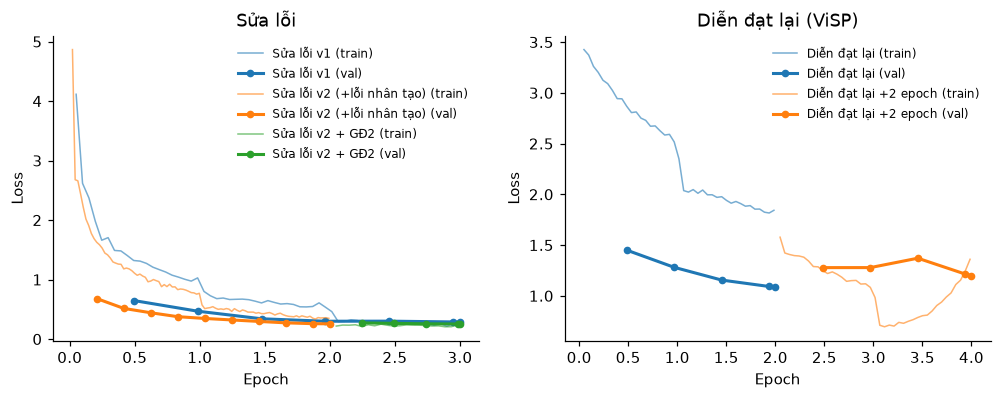

In [2]:
RUNS = {"Sửa lỗi v1": "models/correction/vit5-base", "Sửa lỗi v2 (+lỗi nhân tạo)": "models/correction/vit5-base-aug",
        "Sửa lỗi v2 + GĐ2": "models/correction/vit5-base-aug-ft", "Diễn đạt lại": "models/paraphrase/vit5-base",
        "Diễn đạt lại +2 epoch": "models/paraphrase/vit5-base-ep4"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (name, d) in enumerate(RUNS.items()):
    p = Path(d) / "train_summary.json"
    if not p.exists():
        continue
    hist = pd.DataFrame(load(p)["log_history"])
    ax = axes[0] if name.startswith("Sửa") else axes[1]
    offset = 2 if name.endswith(("+2 epoch", "GĐ2")) else 0  # huấn luyện tiếp từ mô hình đã chạy 2 epoch
    tr, ev = hist.dropna(subset=["loss"]), hist.dropna(subset=["eval_loss"]).drop_duplicates("step")
    line, = ax.plot(tr.epoch + offset, tr.loss, lw=1, alpha=0.6, label=f"{name} (train)")
    ax.plot(ev.epoch + offset, ev.eval_loss, "o-", color=line.get_color(), lw=2, ms=4, label=f"{name} (val)")
axes[0].set(title="Sửa lỗi", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Diễn đạt lại (ViSP)", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "03_loss_curves.png")

Giai đoạn 2 (sửa lỗi) và "+2 epoch" (diễn đạt lại) huấn luyện tiếp từ mô hình 2 epoch, nên được vẽ nối tiếp từ epoch 2. Với diễn đạt lại, huấn luyện tiếp làm val loss **tăng** (1,09 -> 1,20): lr khởi động lại đẩy mô hình ra khỏi điểm tốt, train loss giảm mạnh ở epoch 3 (học thuộc), nên giữ mô hình 2 epoch.

## Stress test theo kiểu lỗi: đúng ở phương án đầu / trong top-3

,WER đầu vào,v1 top-1,v1 top-3,v2+GĐ2 top-1,v2+GĐ2 top-3
Kiểu lỗi,,,,,
Câu đã đúng (sửa quá tay),0.0%,90.0%,93.0%,87.0%,92.5%
Không dấu cả câu,74.3%,23.8%,36.8%,45.8%,59.5%
Đảo chữ,13.2%,34.8%,43.0%,68.2%,78.8%
Bấm hụt/thiếu chữ,12.8%,22.2%,27.5%,42.0%,50.7%
Phím bên cạnh,12.6%,30.0%,40.0%,58.2%,68.2%
Phím đúp,13.1%,68.8%,75.2%,80.2%,89.8%
Sai dấu thanh/dấu chữ,12.4%,24.8%,33.0%,58.2%,69.8%
Gõ nhanh: không dấu + 1–2 lỗi gõ,76.4%,6.5%,10.2%,26.5%,36.8%


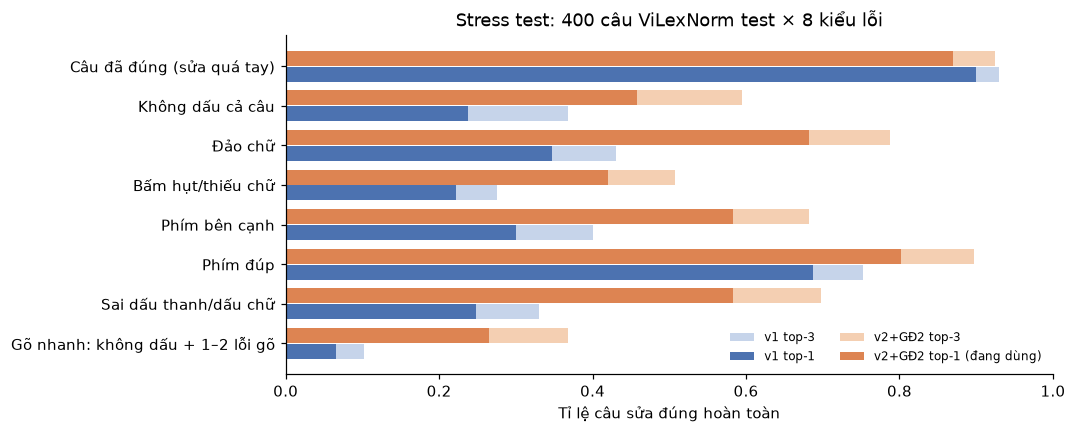

In [3]:
from src.correction.stress_test import LABELS
stress = {n: load(f"outputs/metrics/stress_{n}.json")["categories"] for n in ["vit5-base", "vit5-base-aug-ft"]}
rows = []
for cat, label in LABELS.items():
    rows.append({"Kiểu lỗi": label, "WER đầu vào": stress["vit5-base"][cat]["wer_input"],
                 "v1 top-1": stress["vit5-base"][cat]["exact_match"], "v1 top-3": stress["vit5-base"][cat]["exact_match_top3"],
                 "v2+GĐ2 top-1": stress["vit5-base-aug-ft"][cat]["exact_match"],
                 "v2+GĐ2 top-3": stress["vit5-base-aug-ft"][cat]["exact_match_top3"]})
st = pd.DataFrame(rows).set_index("Kiểu lỗi")
st.to_csv(TAB / "03_stress_top1_top3.csv")
fig, ax = plt.subplots(figsize=(9, 4))
y = range(len(st))
ax.barh([i + 0.2 for i in y], st["v1 top-3"], 0.38, color="#c6d4ea", label="v1 top-3")
ax.barh([i + 0.2 for i in y], st["v1 top-1"], 0.38, color="#4C72B0", label="v1 top-1")
ax.barh([i - 0.2 for i in y], st["v2+GĐ2 top-3"], 0.38, color="#f4cfb2", label="v2+GĐ2 top-3")
ax.barh([i - 0.2 for i in y], st["v2+GĐ2 top-1"], 0.38, color="#DD8452", label="v2+GĐ2 top-1 (đang dùng)")
ax.set_yticks(list(y), st.index); ax.invert_yaxis()
ax.set(xlabel="Tỉ lệ câu sửa đúng hoàn toàn", xlim=(0, 1), title="Stress test: 400 câu ViLexNorm test × 8 kiểu lỗi")
ax.legend(frameon=False, ncol=2, fontsize=8, loc="lower right")
fig.savefig(FIG / "03_stress_top1_top3.png")
st.style.format("{:.1%}")

## Tập test thật

In [4]:
SYSTEMS = {"Chép đầu vào": "baseline_copy", "bmd1905 (có sẵn)": "vietnamese-correction-v2", "v1": "vit5-base",
           "v2": "vit5-base-aug", "v2+GĐ2 (đang dùng)": "vit5-base-aug-ft"}
rows = []
for ds in ["vilexnorm", "vsec", "vec"]:
    for name, f in SYSTEMS.items():
        m = load(f"outputs/metrics/correction_{ds}_test_{f}.json")
        rows.append({"Tập test": ds, "Hệ thống": name, "WER": m["wer"], "Đúng hết": m["exact_match"],
                     "Top-3": m.get("exact_match_top3"), "F0.5": m.get("f0.5"), "Sửa quá tay": m.get("overcorrection_rate")})
real = pd.DataFrame(rows).set_index(["Tập test", "Hệ thống"])
real.to_csv(TAB / "03_real_test.csv")
real.style.format("{:.1%}", na_rep="–")

## RQ3: diễn đạt thẳng câu lỗi hay sửa lỗi trước?

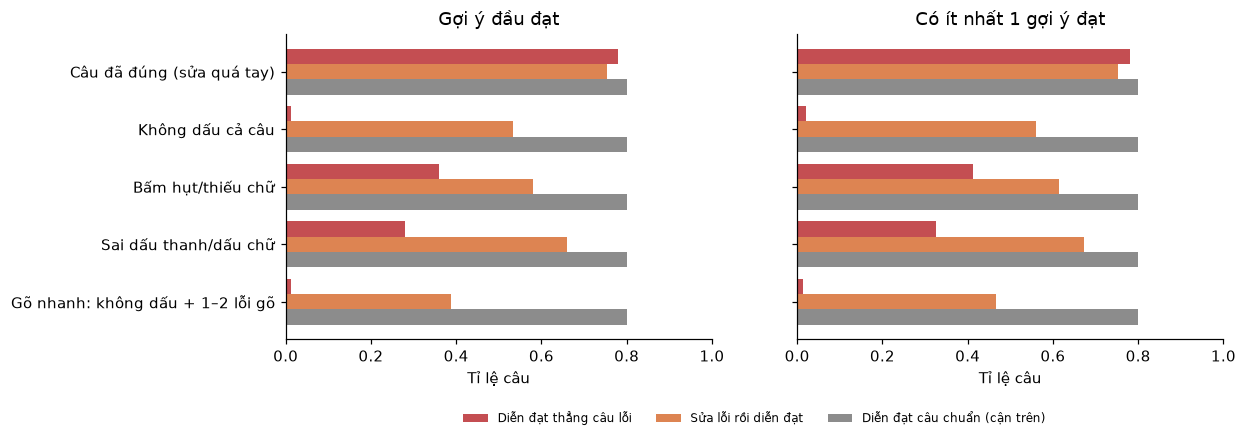

In [5]:
from src.pipeline.rq3 import CATEGORIES, SYSTEMS as RQ3_SYSTEMS
rq3 = load("outputs/metrics/rq3.json")["results"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, key, title in [(axes[0], "top1_ok", "Gợi ý đầu đạt"), (axes[1], "any_ok", "Có ít nhất 1 gợi ý đạt")]:
    df = pd.DataFrame({RQ3_SYSTEMS[s]: [rq3[s][c][key] for c in CATEGORIES] for s in RQ3_SYSTEMS},
                      index=[LABELS[c] for c in CATEGORIES])
    df.plot.barh(ax=ax, width=0.8, color=["#C44E52", "#DD8452", "#8C8C8C"], legend=ax is axes[1])
    ax.set(title=title, xlim=(0, 1), xlabel="Tỉ lệ câu")
    ax.invert_yaxis()
axes[1].legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(-0.1, -0.2))
fig.savefig(FIG / "03_rq3.png")
pd.DataFrame({(RQ3_SYSTEMS[s], k): [rq3[s][c][k] for c in CATEGORIES] for s in RQ3_SYSTEMS
              for k in ["top1_ok", "any_ok", "clean", "keeps_meaning"]},
             index=[LABELS[c] for c in CATEGORIES]).style.format("{:.0%}")

## 20 lỗi tiêu biểu của mô hình đang dùng (v2+GĐ2)

Chọn từ các câu sai trên test ViLexNorm và VSEC, phân loại thủ công. Bảng đầy đủ: `reports/tables/03_error_examples.{csv,md}`.

In [6]:
# (dataset, chỉ số dòng trong test, loại lỗi, nhận xét) — phân loại thủ công sau khi đọc dự đoán
ERRORS = [
    ("vilexnorm", 0, "Viết tắt mơ hồ", "'m' = mình/mày; mô hình chọn 'mày' dù câu dùng 'mình'"),
    ("vilexnorm", 898, "Viết tắt mơ hồ", "'c' = chị/cậu; không đủ ngữ cảnh"),
    ("vilexnorm", 854, "Viết tắt mơ hồ", "'ck' thường là chồng nhưng ở đây người gán nhãn hiểu là 'chị'"),
    ("vilexnorm", 394, "Viết tắt mơ hồ", "'nk' (nhưng) bị đọc thành 'nữa'"),
    ("vilexnorm", 383, "Sửa thành từ có thật nhưng sai", "'xịu' -> 'chịu' thay vì 'xịt'"),
    ("vilexnorm", 294, "Sửa thành từ có thật nhưng sai", "'dăng' -> 'đang' thay vì 'văng'"),
    ("vilexnorm", 962, "Sửa thành từ có thật nhưng sai", "'dzú' -> 'vợ' thay vì 'vú' (đổi nghĩa)"),
    ("vsec", 206, "Sửa thành từ có thật nhưng sai", "'Luống' -> 'Lượng' thay vì 'Luồng' (thuật ngữ)"),
    ("vilexnorm", 648, "Sửa quá tay", "'ruby' (màu son) bị đổi thành 'rực rỡ'"),
    ("vilexnorm", 616, "Sửa quá tay", "từ mượn 'lane' bị đổi thành 'lăn'"),
    ("vilexnorm", 191, "Sửa quá tay", "'quá hời' đúng nhưng bị đổi thành 'quá trời'"),
    ("vsec", 401, "Sửa quá tay", "sửa đúng 'hê' nhưng đổi luôn 'đơn giá' -> 'đơn giản'"),
    ("vsec", 147, "Mất/đổi nội dung", "'tuấn hoàn' -> 'kiệt quệ': đổi hẳn nghĩa câu"),
    ("vsec", 42, "Mất/đổi nội dung", "'tựu lực' -> 'nỗ lực' thay vì 'tự lực'"),
    ("vilexnorm", 557, "Mất/đổi nội dung", "tên riêng 'Mi nơ' bị đổi thành 'Mixi'"),
    ("vsec", 908, "Bỏ sót lỗi", "'gặt bỏ' là từ có thật nên không bị sửa (đúng: 'gạt bỏ')"),
    ("vsec", 368, "Bỏ sót lỗi", "'dạy thì' cần ngữ cảnh mới biết là 'dậy thì'"),
    ("vilexnorm", 27, "Lỗi nhãn", "nhãn tự đổi '2005' -> '2006'; mô hình giữ số đúng như câu gốc"),
    ("vilexnorm", 503, "Lỗi nhãn", "mô hình viết '2tr' -> '2 triệu' (hợp lý), nhãn giữ nguyên nên bị tính sai"),
    ("vsec", 659, "Lỗi nhãn", "mô hình sửa 'Hà nội' -> 'Hà Nội' đúng, nhãn bỏ sót"),
]
preds = {ds: pd.read_json(f"outputs/predictions/correction_{ds}_test_vit5-base-aug-ft.jsonl", lines=True)
         for ds in ["vilexnorm", "vsec"]}
ex = pd.DataFrame([{"Loại lỗi": cat, "Tập": ds, "Đầu vào": preds[ds].source[i], "Mô hình": preds[ds].pred[i],
                    "Nhãn": preds[ds].target[i], "Nhận xét": note} for ds, i, cat, note in ERRORS])
ex.to_csv(TAB / "03_error_examples.csv", index=False, encoding="utf-8-sig")
(TAB / "03_error_examples.md").write_text(ex.to_markdown(index=False), encoding="utf-8")
ex.groupby("Loại lỗi", sort=False).size().to_frame("số ví dụ")

,số ví dụ
Loại lỗi,
Viết tắt mơ hồ,4
Sửa thành từ có thật nhưng sai,4
Sửa quá tay,4
Mất/đổi nội dung,3
Bỏ sót lỗi,2
Lỗi nhãn,3


In [7]:
pd.set_option("display.max_colwidth", 120)
ex[["Loại lỗi", "Đầu vào", "Mô hình", "Nhãn", "Nhận xét"]]

,Loại lỗi,Đầu vào,Mô hình,Nhãn,Nhận xét
0,Viết tắt mơ hồ,"K nên bới đồ ăn thật nhưng cũng nên đổi người yêu, nếu là ng yêu mình thì a ấy sẽ tự lấy phần nạc cho m rồi, m cũng ...","Không nên bới đồ ăn thật nhưng cũng nên đổi người yêu, nếu là người yêu mình thì anh ấy sẽ tự lấy phần nạc cho mày r...","Không nên bới đồ ăn thật nhưng cũng nên đổi người yêu, nếu là người yêu mình thì anh ấy sẽ tự lấy phần nạc cho mình ...",'m' = mình/mày; mô hình chọn 'mày' dù câu dùng 'mình'
1,Viết tắt mơ hồ,Việc c cần làm không phải là thay đổi bản thân mà là đổi chồng,Việc chị cần làm không phải là thay đổi bản thân mà là đổi chồng,Việc cậu cần làm không phải là thay đổi bản thân mà là đổi chồng,'c' = chị/cậu; không đủ ngữ cảnh
2,Viết tắt mơ hồ,mai mặc thử váy body k ck,mai mặc thử váy body không chồng,mai mặc thử váy body không chị,'ck' thường là chồng nhưng ở đây người gán nhãn hiểu là 'chị'
3,Viết tắt mơ hồ,Mk cũng k ăn dk thịt mỡ nk thay vì bới mk chọn k ăn nữa,Mình cũng không ăn được thịt mỡ nữa thay vì bới mình chọn không ăn nữa,Mình cũng không ăn được thịt mỡ nhưng thay vì bới mình chọn không ăn nữa,'nk' (nhưng) bị đọc thành 'nữa'
4,Sửa thành từ có thật nhưng sai,nghe nói gọt ra còn ít xịu à,nghe nói gọt ra còn ít chịu à,nghe nói gọt ra còn ít xịt à,'xịu' -> 'chịu' thay vì 'xịt'
5,Sửa thành từ có thật nhưng sai,Nước dăng xuyên màn hình,Nước đang xuyên màn hình,Nước văng xuyên màn hình,'dăng' -> 'đang' thay vì 'văng'
6,Sửa thành từ có thật nhưng sai,Còn dzú của tôi nữa,Còn vợ của tôi nữa,Còn vú của tôi nữa,'dzú' -> 'vợ' thay vì 'vú' (đổi nghĩa)
7,Sửa thành từ có thật nhưng sai,"Luống thay thế Có lỗi mạng, server bảo trì thì hệ thống sẽ hiển thị thông báo tương ứng với lỗi.","Lượng thay thế Có lỗi mạng, server bảo trì thì hệ thống sẽ hiển thị thông báo tương ứng với lỗi.","Luồng thay thế Có lỗi mạng, server bảo trì thì hệ thống sẽ hiển thị thông báo tương ứng với lỗi.",'Luống' -> 'Lượng' thay vì 'Luồng' (thuật ngữ)
8,Sửa quá tay,Màu cam nâu supernova của Bobbi Brown vs màu đỏ ruby của Kiko ạ Ọ v Ọ,Màu cam nâu supernova của Bobbi Brown với màu đỏ rực rỡ của Kiko ạ Ọ v Ọ,Màu cam nâu supernova của Bobbi Brown với màu đỏ ruby của Kiko ạ Ọ v Ọ,'ruby' (màu son) bị đổi thành 'rực rỡ'
9,Sửa quá tay,đã kẹt gặp mấy cha xe lớn lane xe máy đi hàng 3 bố ai mà ko kẹt cho được .,đã kẹt gặp mấy cha xe lớn lăn xe máy đi hàng 3 bố ai mà không kẹt cho được .,đã kẹt gặp mấy cha xe lớn lane xe máy đi hàng 3 bố ai mà không kẹt cho được .,từ mượn 'lane' bị đổi thành 'lăn'


Nhận xét: phần lớn lỗi còn lại là **viết tắt mơ hồ** (một chữ cái ứng với nhiều đại từ, cần ngữ cảnh hội thoại) và **sửa thành từ có thật nhưng sai nghĩa**. Ba trong 20 câu bị tính sai là do **nhãn** (nhãn tự đổi số, hoặc bỏ sót lỗi), nên EM/WER trên test thật hơi thấp hơn chất lượng thực tế. Nguy hiểm nhất là **đổi nội dung** (tuần hoàn → kiệt quệ, đổi tên riêng): vì vậy demo cho chọn 3 phương án và pipeline kiểm tra số/tên/phủ định.